# Avaliação Comparativa dos Modelos de Classificação

## 1. Objetivo

Esta etapa tem como objetivo realizar uma avaliação comparativa dos três modelos de classificação desenvolvidos no projeto de qualidade de vinhos:

- Regressão Logística;
- Random Forest;
- Gradient Boosting.

A análise será realizada a partir das métricas de desempenho já obtidas nos respectivos experimentos, sem modificar os dados, os notebooks ou os resultados originais desenvolvidos pelos integrantes da equipe.

Serão consideradas métricas como acurácia, precisão, recall, F1-score, ROC AUC e Average Precision, além das matrizes de confusão, quando disponíveis.

A avaliação buscará identificar os pontos fortes e as limitações de cada modelo, especialmente na identificação dos vinhos classificados como de qualidade alta (nota igual ou superior a 7).

**Observação:** esta análise é independente e complementar aos experimentos originais. Diferenças nos procedimentos de avaliação, como os limiares de classificação utilizados, serão consideradas na interpretação dos resultados.

## 2. Identificação dos modelos e origem dos resultados

Para esta avaliação, foram considerados três modelos desenvolvidos individualmente pelos integrantes da equipe.

### 2.1 Regressão Logística

Modelo desenvolvido neste projeto individual, utilizando um pipeline composto por RobustScaler e LogisticRegression.

- Dados de treinamento: 814 registros.
- Dados de teste: 204 registros.
- Variáveis preditoras: 11.
- Limiar de classificação selecionado: 0,30, com base na avaliação realizada na etapa de validação.
- Também serão considerados os resultados obtidos com o limiar padrão de 0,50, para permitir uma análise complementar.

### 2.2 Random Forest

Modelo desenvolvido por outro integrante da equipe.

Configurações identificadas no notebook original:

- Número de árvores: 300.
- Random state: 42.
- Balanceamento de classes: balanced.
- Processamento paralelo: n_jobs = -1.
- Limiar de classificação: 0,50 (previsão padrão do método predict).

### 2.3 Gradient Boosting

Modelo desenvolvido por outro integrante da equipe.

Configurações identificadas nos arquivos de resultados:

- Learning rate: 0,05.
- Profundidade máxima: 3.
- Número de estimadores: 100.
- Subsample: 0,8.
- Validação cruzada: StratifiedKFold com 5 divisões.
- Limiar de classificação: 0,50 (previsão padrão do método predict).

### 2.4 Cuidados metodológicos

Os resultados serão utilizados conforme registrados nos experimentos originais, sem alteração dos arquivos ou reexecução dos modelos desenvolvidos pelos colegas.

As diferenças de configuração, limiar de classificação e procedimentos de avaliação serão consideradas na interpretação dos resultados. Quando não houver informações suficientes para confirmar a equivalência entre os experimentos, essa limitação será explicitada.

In [2]:

import pandas as pd

# Organiza os resultados dos três modelos em uma tabela.
# Os valores são os resultados já obtidos nos experimentos originais.
# Nenhum modelo será treinado novamente nesta etapa.

resultados = pd.DataFrame({
    "Modelo": [
        "Regressão Logística (limiar 0,30)",
        "Random Forest (limiar 0,50)",
        "Gradient Boosting (limiar 0,50)"
    ],
    "Acurácia": [
        0.8529,
        0.9070,
        0.8676
    ],
    "Precisão": [
        0.4545,
        0.6540,
        0.5000
    ],
    "Recall": [
        0.5556,
        0.6300,
        0.7778
    ],
    "F1-score": [
        0.5000,
        0.6420,
        0.6087
    ],
    "ROC AUC": [
        None,
        0.9220,
        0.9159
    ],
    "Average Precision": [
        None,
        0.6980,
        0.6763
    ]
})

# Exibe os resultados com quatro casas decimais.
# Exibe a tabela sem o índice numérico e com as colunas organizadas.
display(
    resultados.style
    .format({
        "Acurácia": "{:.2%}",
        "Precisão": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC AUC": "{:.2%}",
        "Average Precision": "{:.2%}"
    }, na_rep="Não informado")
)


,Modelo,Acurácia,Precisão,Recall,F1-score,ROC AUC,Average Precision
0,"Regressão Logística (limiar 0,30)",85.29%,45.45%,55.56%,50.00%,Não informado,Não informado
1,"Random Forest (limiar 0,50)",90.70%,65.40%,63.00%,64.20%,92.20%,69.80%
2,"Gradient Boosting (limiar 0,50)",86.76%,50.00%,77.78%,60.87%,91.59%,67.63%


## 3. Análise preliminar dos resultados

A análise inicial dos resultados permite observar diferenças no desempenho dos três modelos.

O **Random Forest** apresentou os maiores valores de acurácia (90,70%), precisão (65,40%), F1-score (64,20%), ROC AUC (92,20%) e Average Precision (69,80%). Esses resultados indicam um desempenho equilibrado entre a identificação correta dos vinhos da classe Alta e a capacidade geral de discriminação entre as classes.

O **Gradient Boosting** apresentou o maior recall (77,78%), demonstrando maior capacidade de identificar vinhos classificados como Alta. Entretanto, sua precisão foi de 50%, indicando maior ocorrência de falsos positivos.

A **Regressão Logística**, avaliada com limiar de 0,30, apresentou acurácia de 85,29%, precisão de 45,45%, recall de 55,56% e F1-score de 50%.

É importante considerar que a Regressão Logística utilizou um limiar de classificação diferente dos demais modelos. Portanto, os resultados representam pontos de operação distintos e devem ser interpretados com cautela.

Esta análise é preliminar e não estabelece uma conclusão definitiva sobre o melhor modelo. Será necessário considerar também as matrizes de confusão, os procedimentos de validação e as características de cada abordagem.

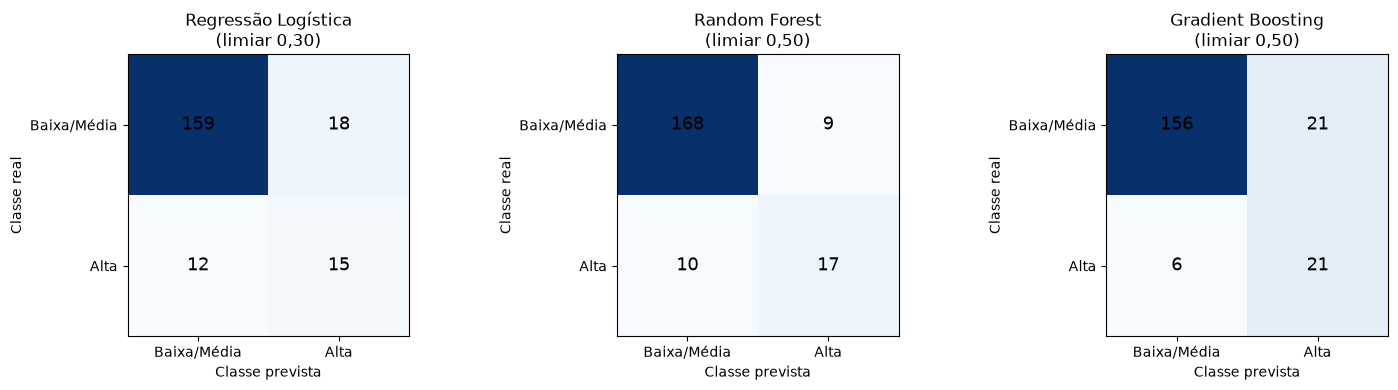

In [3]:

import matplotlib.pyplot as plt
import numpy as np

# Matrizes de confusão dos três modelos.
# A organização segue: [[TN, FP], [FN, TP]].
# Os valores são provenientes dos resultados já registrados.

matrizes = {
    "Regressão Logística\n(limiar 0,30)": np.array([
        [159, 18],
        [12, 15]
    ]),
    "Random Forest\n(limiar 0,50)": np.array([
        [168, 9],
        [10, 17]
    ]),
    "Gradient Boosting\n(limiar 0,50)": np.array([
        [156, 21],
        [6, 21]
    ])
}

# Cria uma área com três gráficos, um para cada modelo.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (nome, matriz) in zip(axes, matrizes.items()):

    # Exibe a matriz como um mapa de calor.
    imagem = ax.imshow(matriz, cmap="Blues")

    # Adiciona os valores dentro de cada quadrante.
    for linha in range(2):
        for coluna in range(2):
            ax.text(
                coluna,
                linha,
                matriz[linha, coluna],
                ha="center",
                va="center",
                fontsize=13
            )

    # Identifica os eixos e as classes.
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Baixa/Média", "Alta"])
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["Baixa/Média", "Alta"])

    ax.set_xlabel("Classe prevista")
    ax.set_ylabel("Classe real")
    ax.set_title(nome)

# Ajusta o espaçamento entre os gráficos.
plt.tight_layout()
plt.show()


## 4. Análise das matrizes de confusão

As matrizes de confusão permitem observar os tipos de erros cometidos por cada modelo na classificação dos vinhos.

### 4.1 Regressão Logística

O modelo apresentou 159 verdadeiros negativos e 15 verdadeiros positivos. Foram identificados 18 falsos positivos e 12 falsos negativos.

Com o limiar de 0,30, o modelo conseguiu identificar 15 dos 27 vinhos da classe Alta, mas também classificou incorretamente 18 vinhos da classe Baixa/Média.

### 4.2 Random Forest

O Random Forest apresentou 168 verdadeiros negativos e 17 verdadeiros positivos, com 9 falsos positivos e 10 falsos negativos.

Entre os três modelos, apresentou a menor quantidade de falsos positivos, indicando maior capacidade de evitar classificações incorretas de vinhos Baixa/Média como Alta.

### 4.3 Gradient Boosting

O Gradient Boosting apresentou 156 verdadeiros negativos e 21 verdadeiros positivos, com 21 falsos positivos e 6 falsos negativos.

Entre os três modelos, apresentou a menor quantidade de falsos negativos e o maior número de verdadeiros positivos. Esse resultado está relacionado ao maior recall observado para a classe Alta.

Entretanto, também apresentou a maior quantidade de falsos positivos, indicando maior tendência a classificar vinhos Baixa/Média como Alta.

### 4.4 Comparação geral

A análise evidencia diferentes comportamentos entre os modelos:

- O Random Forest apresentou menor quantidade de falsos positivos.
- O Gradient Boosting apresentou menor quantidade de falsos negativos.
- A Regressão Logística apresentou resultados intermediários em relação a esses dois tipos de erro.

Portanto, a escolha do modelo depende também do objetivo da classificação. Caso seja prioritário identificar o maior número possível de vinhos de qualidade Alta, o recall ganha importância. Caso seja prioritário evitar classificações incorretas como Alta, a precisão deve receber maior atenção.

As diferenças nos limiares de classificação devem ser consideradas antes de estabelecer uma comparação definitiva.

## 5. Comparação do equilíbrio entre precisão e recall

O F1-score representa a média harmônica entre precisão e recall, sendo especialmente relevante em problemas de classificação com classes desbalanceadas.

Na comparação dos resultados:

- **Random Forest:** apresentou F1-score de 64,20%, indicando o melhor equilíbrio entre precisão e recall entre os três modelos nos limiares avaliados.
- **Gradient Boosting:** apresentou F1-score de 60,87%, com maior recall, mas menor precisão.
- **Regressão Logística:** apresentou F1-score de 50,00%, considerando o limiar de 0,30.

Os resultados indicam que o Random Forest obteve o maior F1-score, enquanto o Gradient Boosting demonstrou maior capacidade de identificar vinhos da classe Alta.

Essa diferença evidencia que o melhor desempenho depende do objetivo da classificação. Um modelo com maior recall pode ser preferível quando se deseja reduzir a quantidade de vinhos de qualidade Alta não identificados. Por outro lado, um modelo com maior precisão pode ser mais adequado quando se deseja reduzir falsos positivos.

A comparação deve ser interpretada considerando os diferentes limiares de classificação utilizados nos experimentos.

## 6. Comparação visual das métricas

Para facilitar a interpretação dos resultados, será construído um gráfico de barras comparando acurácia, precisão, recall e F1-score dos três modelos.

A visualização permite identificar as diferenças de desempenho e observar os pontos fortes e limitações de cada abordagem.

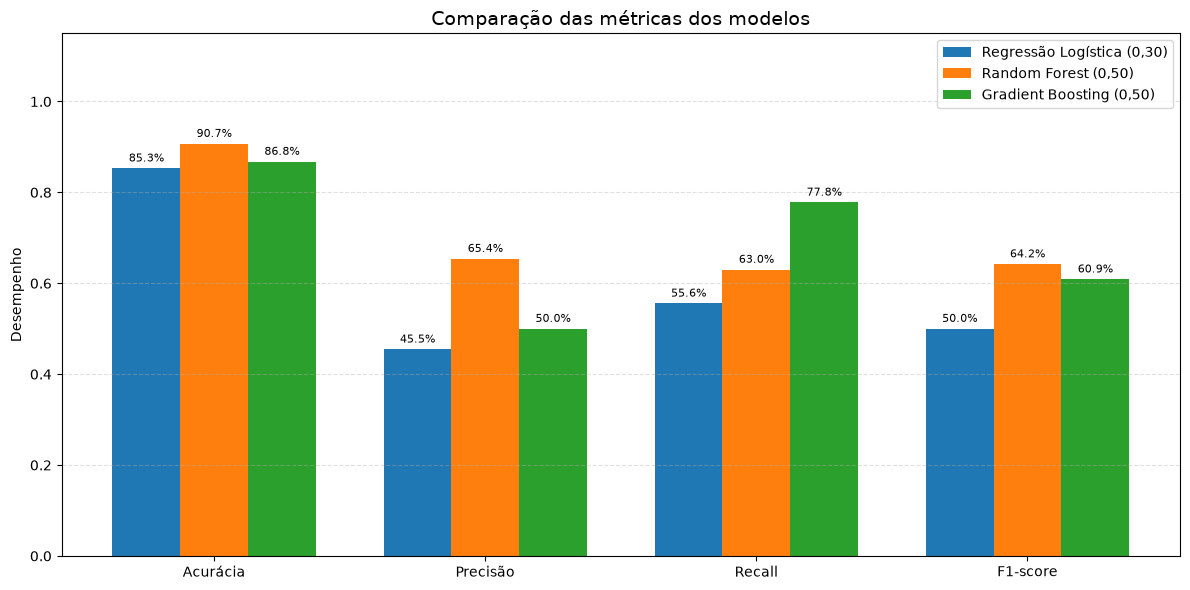

In [5]:
# Importação da biblioteca utilizada na visualização
import matplotlib.pyplot as plt
import numpy as np

# Seleção das métricas para comparação
metricas = ["Acurácia", "Precisão", "Recall", "F1-score"]

# Valores dos modelos
modelos = {
    "Regressão Logística (0,30)": [0.8529, 0.4545, 0.5556, 0.5000],
    "Random Forest (0,50)": [0.9070, 0.6540, 0.6300, 0.6420],
    "Gradient Boosting (0,50)": [0.8676, 0.5000, 0.7778, 0.6087]
}

# Definição da posição das barras
x = np.arange(len(metricas))
largura = 0.25

# Criação do gráfico
fig, ax = plt.subplots(figsize=(12, 6))

for i, (nome, valores) in enumerate(modelos.items()):
    deslocamento = (i - 1) * largura

    barras = ax.bar(
        x + deslocamento,
        valores,
        largura,
        label=nome
    )

    # Exibição dos valores percentuais acima das barras
    ax.bar_label(
        barras,
        labels=[f"{valor:.1%}" for valor in valores],
        padding=3,
        fontsize=8
    )

# Configuração dos eixos e do título
ax.set_title("Comparação das métricas dos modelos", fontsize=14)
ax.set_ylabel("Desempenho")
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [6]:
# Organização das métricas dos modelos para comparação
resultados = pd.DataFrame({
    "Modelo": [
        "Regressão Logística (0,30)",
        "Regressão Logística (0,50)",
        "Random Forest (0,50)",
        "Gradient Boosting (0,50)"
    ],
    "Acurácia": [0.8529, 0.8971, 0.9070, 0.8676],
    "Precisão": [0.4545, 0.6500, 0.6540, 0.5000],
    "Recall": [0.5556, 0.4815, 0.6300, 0.7778],
    "F1-score": [0.5000, 0.5532, 0.6420, 0.6087],
    "ROC AUC": [None, None, 0.9220, 0.9159],
    "Average Precision": [None, None, 0.6980, 0.6763]
})

# Exibição das métricas em formato percentual
display(
    resultados.style
    .format({
        "Acurácia": "{:.2%}",
        "Precisão": "{:.2%}",
        "Recall": "{:.2%}",
        "F1-score": "{:.2%}",
        "ROC AUC": "{:.2%}",
        "Average Precision": "{:.2%}"
    }, na_rep="Não informado")
)

,Modelo,Acurácia,Precisão,Recall,F1-score,ROC AUC,Average Precision
0,"Regressão Logística (0,30)",85.29%,45.45%,55.56%,50.00%,Não informado,Não informado
1,"Regressão Logística (0,50)",89.71%,65.00%,48.15%,55.32%,Não informado,Não informado
2,"Random Forest (0,50)",90.70%,65.40%,63.00%,64.20%,92.20%,69.80%
3,"Gradient Boosting (0,50)",86.76%,50.00%,77.78%,60.87%,91.59%,67.63%


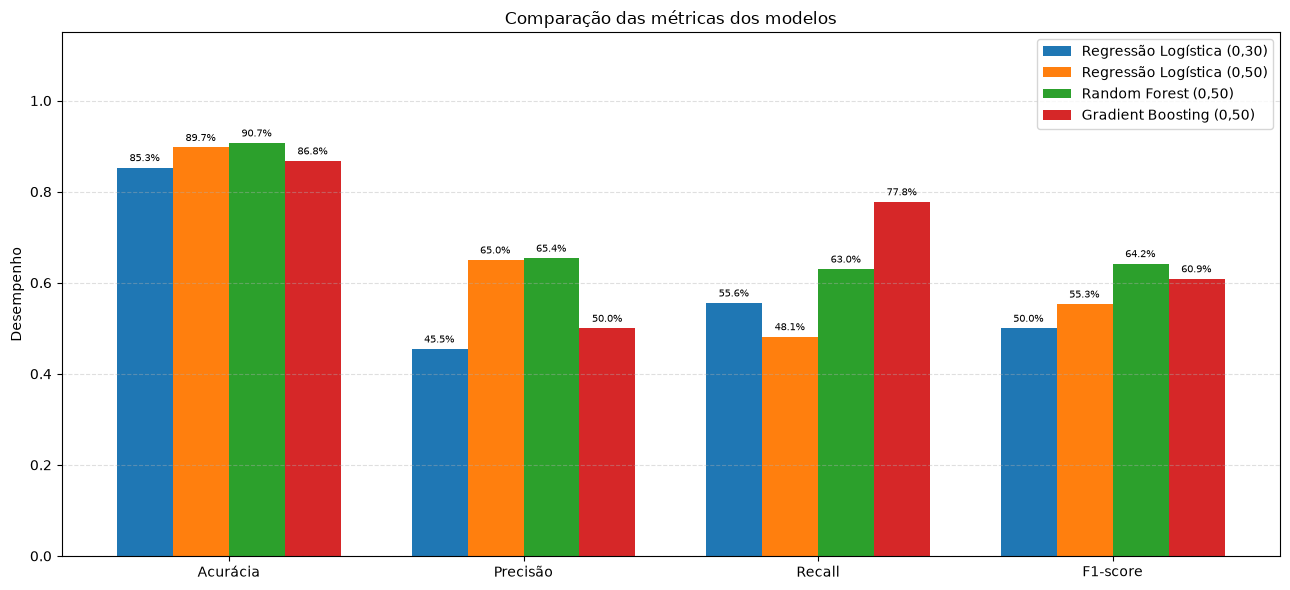

In [7]:
# Comparação visual das métricas dos modelos
import matplotlib.pyplot as plt
import numpy as np

metricas = ["Acurácia", "Precisão", "Recall", "F1-score"]

modelos = {
    "Regressão Logística (0,30)": [0.8529, 0.4545, 0.5556, 0.5000],
    "Regressão Logística (0,50)": [0.8971, 0.6500, 0.4815, 0.5532],
    "Random Forest (0,50)": [0.9070, 0.6540, 0.6300, 0.6420],
    "Gradient Boosting (0,50)": [0.8676, 0.5000, 0.7778, 0.6087]
}

# Posições das métricas no eixo horizontal
x = np.arange(len(metricas))
largura = 0.19

fig, ax = plt.subplots(figsize=(13, 6))

# Criação das barras de cada modelo
for i, (nome, valores) in enumerate(modelos.items()):
    deslocamento = (i - 1.5) * largura

    barras = ax.bar(
        x + deslocamento,
        valores,
        largura,
        label=nome
    )

    # Exibição dos valores percentuais
    ax.bar_label(
        barras,
        labels=[f"{valor:.1%}" for valor in valores],
        padding=3,
        fontsize=7
    )

ax.set_title("Comparação das métricas dos modelos")
ax.set_ylabel("Desempenho")
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.15)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 7. Comparação dos modelos utilizando o limiar de 0,50

Para tornar a comparação mais equilibrada, foram analisados os resultados dos três modelos utilizando o limiar padrão de classificação de 0,50.

Nessa configuração, o Random Forest apresentou a maior acurácia (90,70%), precisão (65,40%) e F1-score (64,20%).

O Gradient Boosting apresentou o maior recall (77,78%), demonstrando maior capacidade de identificar vinhos pertencentes à classe Alta. Entretanto, sua precisão foi menor (50,00%), indicando uma quantidade maior de falsos positivos.

A Regressão Logística apresentou acurácia de 89,71% e F1-score de 55,32%, ficando abaixo dos outros dois modelos nessa comparação.

De maneira geral, o Random Forest apresentou o melhor equilíbrio entre as métricas avaliadas, enquanto o Gradient Boosting se destacou na identificação da classe minoritária.

É importante ressaltar que essa análise considera os resultados disponíveis dos experimentos realizados, sem garantir que todos os modelos tenham passado pelo mesmo processo de otimização ou validação.

## 8. Disponibilidade das métricas ROC AUC e Average Precision

As métricas ROC AUC e Average Precision estão disponíveis para os modelos Random Forest e Gradient Boosting, permitindo avaliar sua capacidade de distinguir as classes considerando diferentes limiares de classificação.

Para a Regressão Logística, esses valores não foram incluídos na comparação, pois os resultados de probabilidades previstos necessários para seu cálculo não estão disponíveis no conjunto de métricas utilizado nesta análise.

Dessa forma, os valores foram identificados como não informados, evitando estimativas ou cálculos sem os dados necessários.

Essa limitação deverá ser considerada na interpretação comparativa dos modelos.

## 9. Limitações da avaliação comparativa

A avaliação comparativa foi construída a partir dos resultados já obtidos nos experimentos individuais dos modelos.

Algumas limitações devem ser consideradas:

- Os modelos foram avaliados com diferentes estratégias de desenvolvimento e otimização.
- A Regressão Logística foi apresentada com dois limiares de classificação: 0,30 e 0,50.
- As métricas ROC AUC e Average Precision não estão disponíveis para a Regressão Logística nesta análise.
- Os resultados refletem o desempenho observado no conjunto de teste utilizado nos experimentos.

Essas limitações não impedem a comparação, mas precisam ser consideradas para evitar conclusões que ultrapassem o que os resultados permitem afirmar.

## 10. Conclusão da avaliação comparativa

A avaliação comparativa permitiu analisar o desempenho de três algoritmos de classificação aplicados à identificação da qualidade dos vinhos: Regressão Logística, Random Forest e Gradient Boosting.

Os resultados demonstraram diferenças importantes entre os modelos.

O **Random Forest** apresentou os maiores valores de acurácia (90,70%), precisão (65,40%) e F1-score (64,20%) entre os resultados comparados com limiar de 0,50. Esses indicadores demonstram um equilíbrio mais favorável entre a identificação correta da classe Alta e a redução de falsos positivos.

O **Gradient Boosting** apresentou o maior recall (77,78%), identificando 21 dos 27 vinhos pertencentes à classe Alta. Entretanto, também apresentou maior quantidade de falsos positivos, indicando que sua capacidade de identificar a classe minoritária veio acompanhada de mais classificações incorretas nessa categoria.

A **Regressão Logística** apresentou resultados distintos conforme o limiar utilizado. Com 0,30, seu recall aumentou em relação ao limiar de 0,50, mas houve redução na precisão e na acurácia. Essa observação demonstra a influência da escolha do limiar sobre o comportamento de um classificador.

Portanto, não existe uma única métrica capaz de determinar isoladamente o melhor modelo. A escolha depende do objetivo do problema e da importância atribuída à identificação dos vinhos de qualidade Alta, à redução de falsos positivos e ao equilíbrio geral das classificações.

Por fim, os resultados devem ser interpretados considerando as diferenças entre os processos de desenvolvimento e otimização dos modelos, bem como as limitações das métricas disponíveis. A comparação oferece uma visão do desempenho observado nos experimentos, mas não representa, por si só, uma validação experimental totalmente controlada entre os algoritmos.